In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=5, suppress=True)
RNG = np.random.default_rng(42)

## 1. LFSR

Для примера авторов берем K = 3, отводы j = (0, 1). Состояние - 3 бита. На каждом шаге младший и средний биты складываются по XOR; старшие биты сдвигаются вправо; новый бит входит слева. (источник - рисунок 3 из статьи)

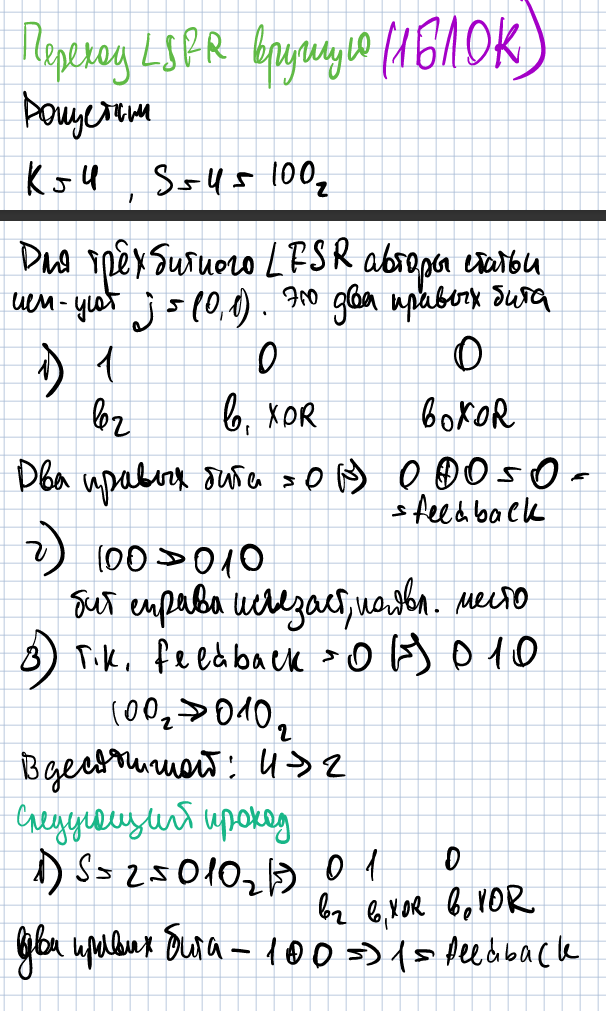

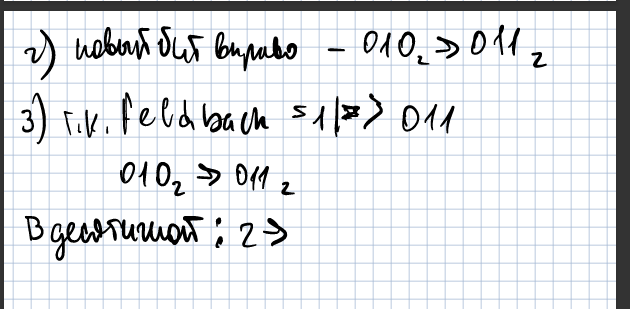

In [2]:
def lfsr_step(state, K, taps):
    feedback = 0
    for bit_index in taps:
        feedback ^= (state >> bit_index) & 1
    return (state >> 1) | (feedback << (K - 1))

print('Первый переход:', format(lfsr_step(4, 3, (0, 1)), '03b'))

Первый переход: 010


In [3]:
states = [4]
for _ in range(8):
    states.append(lfsr_step(states[-1], 3, (0, 1)))
print('Начальное состояние + 8 переходов:', states)
assert states == [4, 2, 5, 6, 7, 3, 1, 4, 2]

Начальное состояние + 8 переходов: [4, 2, 5, 6, 7, 3, 1, 4, 2]


## 2. Собрать $V(s)$ и нормализовать до $U(s)$

Допустим, как в статье, нужна матрица с четырьмя строками и двумя столбцами:

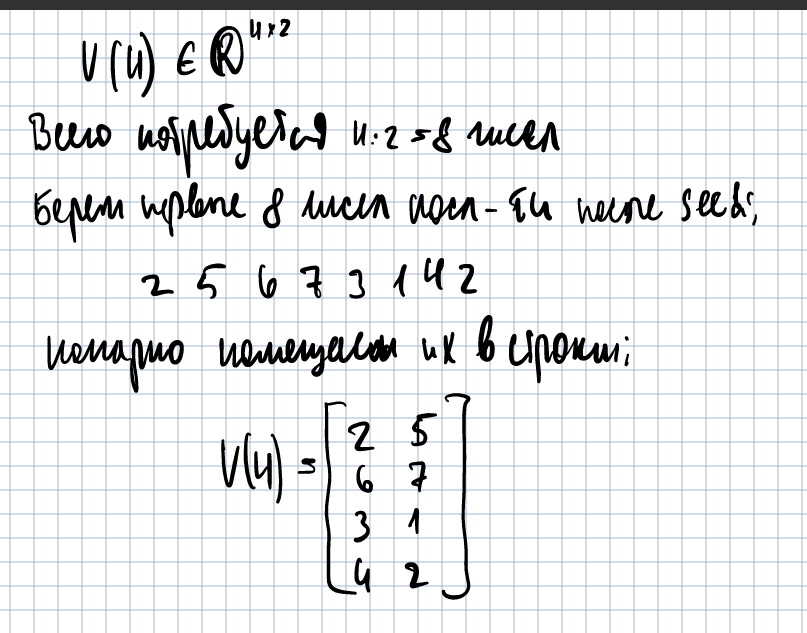

Далее, так как в полученной матрице все элементы - положительные, нужно нормализовать матрицу, так как веса нейросети могут быть как положительными, так и отрицательными, так и близкими к нулю. Поэтому авторы приводят формулу 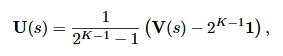

По ней у нас получается, что 1 - матрица из единиц того же размера, что и V(s) => для нашего K=3; 2 ^ k - 1 = 2 ^ 2= 4.

Тогда итоговая матрица будет: 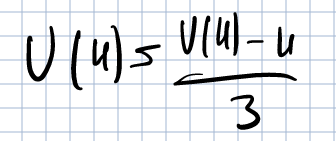

In [4]:
V = np.array(states[1:9], dtype=np.float64).reshape(4, 2)
print('V(4) =', V.astype(int))
assert np.array_equal(V, [[2, 5], [6, 7], [3, 1], [4, 2]])

V(4) = [[2 5]
 [6 7]
 [3 1]
 [4 2]]


In [5]:
K = 3
U = (V - 2**(K - 1)) / (2**(K - 1) - 1)
print('U(4) =', U)
print('Диапазон U:', U.min(), '...', U.max())

U(4) = [[-0.66667  0.33333]
 [ 0.66667  1.     ]
 [-0.33333 -1.     ]
 [ 0.      -0.66667]]
Диапазон U: -1.0 ... 1.0


## 3. Приблизить конкретный блок весов с помощью $U(4)t$

Далее расчитываем систему нормальных уравнений чтобы найти два коэффициента t1 и t2, позволяющих максимально точно восстановить четыре исходных веса.

In [6]:
w = np.array([0., 1., 0., 0.])
G = U.T @ U
h = U.T @ w
print('UᵀU =', G)
print('Uᵀw =', h)

UᵀU = [[1.      0.77778]
 [0.77778 2.55556]]
Uᵀw = [0.66667 1.     ]


In [7]:
t = np.linalg.solve(G, h)
t_pinv = np.linalg.pinv(U) @ w
print('Коэффициенты t:', t)
print('Через псевдообратную U^t*w:', t_pinv)
assert np.allclose(t, t_pinv)
assert np.allclose(t, [75/158, 39/158])

Коэффициенты t: [0.47468 0.24684]
Через псевдообратную U^t*w: [0.47468 0.24684]



Проводим квантование коэффициентов через 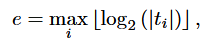

In [8]:
e = int(np.floor(np.log2(np.max(np.abs(t)))))
q = np.clip(np.rint(t / 2**e), -8, 7).astype(int)
t_quant = q * (2.0**e)
print('Общий показатель e =', e)
print('4 битные целые q =', q)
print('Восстановленные коэффициенты =', t_quant)
assert e == -2 and np.array_equal(q, [2, 1])

Общий показатель e = -2
4 битные целые q = [2 1]
Восстановленные коэффициенты = [0.5  0.25]


Рассчитываем ошибку восстановления через сумму квадратов ошибок

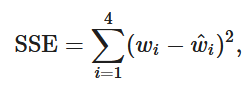

In [9]:
w_hat = U @ t_quant
sse = np.sum((w - w_hat)**2)
mse = np.mean((w - w_hat)**2)
print('w =', w)
print('w восстановленный =', w_hat)
print('SSE =', sse, ' MSE =', mse)
assert np.isclose(sse, 7/16) and np.isclose(mse, 7/64)

w = [0. 1. 0. 0.]
w восстановленный = [-0.25     0.58333 -0.41667 -0.16667]
SSE = 0.4375  MSE = 0.109375


In [10]:
w_float = U @ t
sse_float = np.sum((w - w_float)**2)
print('SSE без квантования:', sse_float)
print('SSE после квантования:', sse)
print('Дополнительная ошибка от квантования:', sse - sse_float)

SSE без квантования: 0.43670886075949367
SSE после квантования: 0.4375
Дополнительная ошибка от квантования: 0.0007911392405063333


Предварительный вывод - два коэффициента действительно приближают четыре исходных числа, но не восстанавливают их точно; квантование добавляет небольшую ошибку. Пока seed зафиксирован равным 4. Следующее улучшение - выбирать seed с минимальной SSE.

---
## 4. Переработка всех 7 seed для K=3

При K=3 всего $2^3-1=7$ ненулевых seed. Для каждого построим отдельную матрицу, найдем t, квантованное $\hat t$ и ошибку. Наш вектор w остается прежним.

In [11]:
def basis_small(seed):
    x = seed
    values = []
    for _ in range(8):
        x = lfsr_step(x, 3, (0, 1))
        values.append(x)
    return (np.array(values).reshape(4, 2) - 4) / 3

In [12]:
rows_small = []
for seed in range(1, 8):
    A = basis_small(seed)
    tj = np.linalg.pinv(A) @ w
    ej = int(np.floor(np.log2(np.max(np.abs(tj)))))
    qj = np.clip(np.rint(tj / 2**ej), -8, 7)
    restored = A @ (qj * 2.0**ej)
    rows_small.append({'seed': seed, 'e': ej, 'q': qj.astype(int).tolist(),
                       'SSE': np.sum((w - restored)**2)})
small_df = pd.DataFrame(rows_small)
display(small_df.round(6))

,seed,e,q,SSE
0,1,-1,"[0, 1]",0.583333
1,2,-2,"[1, -1]",0.576389
2,3,-2,"[-2, 1]",0.604167
3,4,-2,"[2, 1]",0.437500
4,5,-1,"[1, -1]",0.611111
5,6,-2,"[-1, 0]",0.680556
6,7,-2,"[0, -1]",0.791667


In [13]:
best_small = small_df.loc[small_df['SSE'].idxmin()]
print('Лучший seed:', int(best_small['seed']))
print('Минимальная SSE:', best_small['SSE'])
assert int(best_small['seed']) == 4

Лучший seed: 4
Минимальная SSE: 0.4375


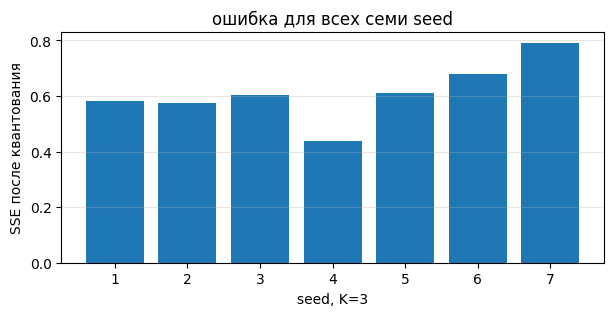

In [14]:
plt.figure(figsize=(7, 3))
plt.bar(small_df.seed.astype(str), small_df.SSE)
plt.xlabel('seed, K=3')
plt.ylabel('SSE после квантования')
plt.title('ошибка для всех семи seed')
plt.grid(axis='y', alpha=0.3)
plt.show()


## 5. Битовый бюджет

Теперь нужно проверить, сколько информации действительно хранится на один исходный вес: seed, общий показатель степени и квантованных коэффициентов. По формуле 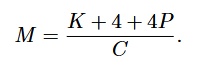

Расчет для 3 и 4 битов соответственно:

In [15]:
CONFIGS = {4: {'K': 16, 'C': 8, 'P': 3},
           3: {'K': 16, 'C': 12, 'P': 4}}
for bits, cfg in CONFIGS.items():
    record_bits = cfg['K'] + 4 + 4 * cfg['P']
    print(bits, 'бит/вес:', record_bits, 'бит на блок /', cfg['C'],
          'весов =', record_bits / cfg['C'], 'бит/вес')
    assert record_bits / cfg['C'] == bits

4 бит/вес: 32 бит на блок / 8 весов = 4.0 бит/вес
3 бит/вес: 36 бит на блок / 12 весов = 3.0 бит/вес


## 6. Перейти к конфигурации авторов K=16

Для K=16 авторы задают отводы (0,1,3,12). Всего имеется 65535 ненулевых seed.

In [16]:
def full_cycle(K, taps):
    cycle = np.empty((1 << K) - 1, dtype=np.uint32)
    cycle[0] = 1
    for i in range(1, len(cycle)):
        cycle[i] = lfsr_step(int(cycle[i - 1]), K, taps)
    pos = np.full(1 << K, -1, dtype=np.int32)
    pos[cycle] = np.arange(len(cycle))
    return cycle, pos

In [17]:
cycle16, positions16 = full_cycle(16, (0, 1, 3, 12))
print('Состояний в цикле:', len(cycle16))
print('Все уникальны:', len(np.unique(cycle16)) == 65535)
print('Возврат в начало:', lfsr_step(int(cycle16[-1]), 16, (0, 1, 3, 12)))
assert len(np.unique(cycle16)) == 65535

Состояний в цикле: 65535
Все уникальны: True
Возврат в начало: 1


## 7. Получение матриц U(s) для многих seed

Здесь векторизуем операцию из 2 пункта - для каждого seed получаем C *  P последующих состояний LFSR и нормализуем.

In [18]:
def bases16(seeds, C, P):
    seeds = np.asarray(seeds, dtype=np.int32)
    starts = positions16[seeds]
    indices = (starts[:, None] + 1 + np.arange(C * P)) % len(cycle16)
    V = cycle16[indices].reshape(-1, C, P).astype(np.float32)
    return (V - 32768.0) / 32767.0

In [19]:
candidate_seeds = RNG.choice(np.arange(1, 65536), size=1024, replace=False)
U4_example = bases16(candidate_seeds[:3], C=8, P=3)
print('Три матрицы 4-bit:', U4_example.shape)
print('Первая матрица U(s), округленно:', np.round(U4_example[0], 3))

Три матрицы 4-bit: (3, 8, 3)
Первая матрица U(s), округленно: [[-0.451  0.274  0.637]
 [-0.181  0.409  0.705]
 [-0.148 -0.574 -0.787]
 [-0.893 -0.947  0.027]
 [ 0.513 -0.243 -0.622]
 [ 0.189 -0.405  0.297]
 [-0.351 -0.676 -0.838]
 [-0.919 -0.96  -0.98 ]]


## 8. Квантование и выбор лучшего seed

При K=16 логика та же, что при K=3, только приходится обрабатывать много блоков. Для расчета ниже - две маленькие функции вместо монолитного блока - первая квантирует коэффициенты, вторая выбирает лучший seed.

In [20]:
def quantize_t(t):
    max_abs = np.max(np.abs(t), axis=-1)
    safe = np.maximum(max_abs, 1e-30)
    exponents = np.floor(np.log2(safe))
    exponents = np.where(max_abs == 0, -8, exponents)
    exponents = np.clip(exponents, -8, 7).astype(np.int8)
    scale = np.exp2(exponents.astype(np.float32))
    q = np.clip(np.rint(t / scale[..., None]), -8, 7).astype(np.int8)
    return q, exponents, q * scale[..., None]

In [21]:
def select_best(blocks, U, seeds):
    pinv = np.linalg.pinv(U)
    coeff = np.einsum('spc,bc->bsp', pinv, blocks, optimize=True)
    q, e, coeff_hat = quantize_t(coeff)
    recon = np.einsum('scp,bsp->bsc', U, coeff_hat, optimize=True)
    errors = np.sum((blocks[:, None, :] - recon)**2, axis=-1)
    best = errors.argmin(axis=1)
    idx = np.arange(len(blocks))
    return {'seed': seeds[best], 'q': q[idx, best], 'e': e[idx, best],
            'recon': recon[idx, best], 'SSE': errors[idx, best]}

## 9. Расчет 3-bit против 4-bit

Авторы статьи проверяли реальные Llama 2/3 по perplexity и zero-shot accuracy. В текущем я использую 1536 синтетических весов из N(0,1) и измеряю NMSE восстановления весов.

Чтобы показать влияние числа вариантов, можем взять вложенные наборы seed - 16 > 64 > 256 > 1024. За счет вложенности лучшая ошибка не может увеличиться при увеличении числа seed.

In [22]:
TOTAL_WEIGHTS = 1536  # кратно 8 и 12
weights = RNG.normal(size=TOTAL_WEIGHTS).astype(np.float32)
print('Всего весов:', len(weights))
print('Оригинальный размер FP16:', weights.astype(np.float16).nbytes, 'байт')
print('Пример исходных весов:', weights[:8])

Всего весов: 1536
Оригинальный размер FP16: 3072 байт
Пример исходных весов: [-0.48279  0.87056  1.47927  1.79437  1.31481 -0.10973  0.35272  0.76682]


In [23]:
SEARCH_SIZES = [16, 64, 256, 1024]
rows = []
packed_inputs = {}
for bits in (4, 3):
    Csize, Psize = CONFIGS[bits]['C'], CONFIGS[bits]['P']
    blocks = weights.reshape(-1, Csize)
    Uall = bases16(candidate_seeds, Csize, Psize)
    for n in SEARCH_SIZES:
        result = select_best(blocks, Uall[:n], candidate_seeds[:n])
        nmse = float(result['SSE'].sum() / np.sum(blocks**2))
        rows.append({'bits': bits, 'seeds_checked': n, 'NMSE': nmse})
        if n == SEARCH_SIZES[-1]:
            packed_inputs[bits] = result
results_df = pd.DataFrame(rows)
display(results_df.round(5))

,bits,seeds_checked,NMSE
0,4,16,0.30374
1,4,64,0.20814
2,4,256,0.14689
3,4,1024,0.10265
4,3,16,0.43562
5,3,64,0.31690
6,3,256,0.24349
7,3,1024,0.18725


In [24]:
for bits in (4, 3):
    curve = results_df[results_df.bits == bits].NMSE.values
    assert np.all(np.diff(curve) <= 1e-7), 'Набор seed должен быть вложенным'
    print(f'{bits}-bit: NMSE {curve[0]:.4f} > {curve[-1]:.4f}')

4-bit: NMSE 0.3037 > 0.1027
3-bit: NMSE 0.4356 > 0.1873


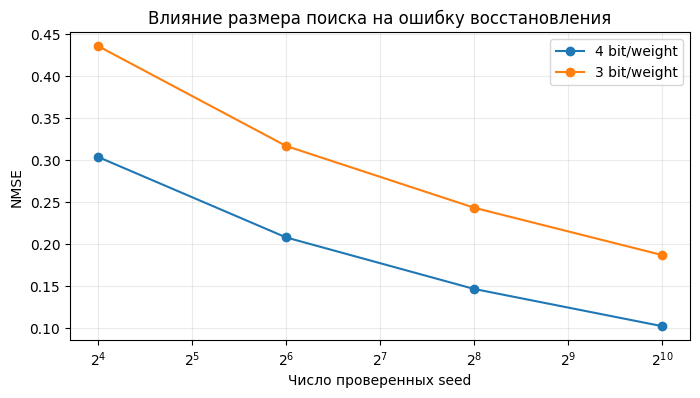

In [25]:
plt.figure(figsize=(8, 4))
for bits in (4, 3):
    d = results_df[results_df.bits == bits]
    plt.plot(d.seeds_checked, d.NMSE, marker='o', label=f'{bits} bit/weight')
plt.xscale('log', base=2)
plt.xlabel('Число проверенных seed')
plt.ylabel('NMSE')
plt.title('Влияние размера поиска на ошибку восстановления')
plt.grid(alpha=0.25)
plt.legend()
plt.show()


## 10. Реальный размер данных



Поля одной упакованной записи - 16-битный seed, 4-битный показатель e, P четырехбитных коэффициентов.

In [26]:
def pack_result(res, P):
    accumulator, used = 0, 0
    data = bytearray()
    for seed, e, q in zip(res['seed'], res['e'], res['q']):
        word = int(seed) | ((int(e) & 15) << 16)
        for j, value in enumerate(q):
            word |= (int(value) & 15) << (20 + 4*j)
        accumulator |= word << used
        used += 20 + 4*P
        while used >= 8:
            data.append(accumulator & 255)
            accumulator >>= 8
            used -= 8
    if used:
        data.append(accumulator & 255)
    return bytes(data)

In [27]:
original_fp16_bytes = weights.astype(np.float16).nbytes
for bits in (4, 3):
    Csize, Psize = CONFIGS[bits]['C'], CONFIGS[bits]['P']
    binary = pack_result(packed_inputs[bits], Psize)
    with open(f'seedlm_{bits}bit_demo.bin', 'wb') as file:
        file.write(binary)
    print(f'{bits}-bit: {len(binary)} байт, сжатие в {original_fp16_bytes/len(binary):.2f} раза')
    assert len(binary) == TOTAL_WEIGHTS * bits // 8

4-bit: 768 байт, сжатие в 4.00 раза
3-bit: 576 байт, сжатие в 5.33 раза


# Контрольный эксперимент



In [28]:
all_seeds = np.arange(1, 65536, dtype=np.int32)

for bits in (4, 3):
    C, P = CONFIGS[bits]["C"], CONFIGS[bits]["P"]
    block = weights[:C].reshape(1, C)

    short = select_best(
        block, bases16(candidate_seeds, C, P), candidate_seeds
    )

    full = select_best(
        block, bases16(all_seeds, C, P), all_seeds
    )

    sse_short = float(short["SSE"][0])
    sse_full = float(full["SSE"][0])
    improvement = (1 - sse_full / sse_short) * 100

    print(f"{bits}-bit: 1024 seed > SSE = {sse_short:.5f}")
    print(f"         65535 seed > SSE = {sse_full:.5f}")
    print(f"         Снижение ошибки: {improvement:.1f}%\n")

    assert sse_full <= sse_short + 1e-6


4-bit: 1024 seed > SSE = 0.53521
         65535 seed > SSE = 0.24618
         Снижение ошибки: 54.0%

3-bit: 1024 seed > SSE = 1.68334
         65535 seed > SSE = 0.63919
         Снижение ошибки: 62.0%



In [29]:
results_df.to_csv('seedlm_guided_results.csv', index=False)
print('seedlm_guided_results.csv')
print('seedlm_4bit_demo.bin и seedlm_3bit_demo.bin')

seedlm_guided_results.csv
seedlm_4bit_demo.bin и seedlm_3bit_demo.bin
